#### IMMUN 306QC
# Single-cell RNA sequencing analysis
*Ralph Estanboulieh (2026)*

*This notebook was created **without** the use of AI.*

Last week, we explored bulk RNA sequencing analysis, including differential gene expression analysis using PyDESeq2, Python's answer to R's DESeq2. In this workshop, we will learn about since-cell RNA sequencing analysis using Scanpy, which is Python's equivalent of Seurat in R. Unlike the sample-level "averaging" that happens in bulk RNA sequencing, single-cell RNA sequencing (scRNA seq) offers cell-level resolution. While initial experiments could only sequencing tens to hundreds of cells, current technology is able to sequence tens to hundreds of thousands of cells. Analyzing this gargantuan amount of data requires special and powerful tools. Luckily, Scanpy is just the perfect tool for this.

## Overview of scRNA seq

Before we analyze scRNA seq data, let's briefly go over the process that starts with a sample and ends with the massive data files on your computer. For a deeper dive into this, check out [this course](https://www.singlecellcourse.org/introduction-to-single-cell-rna-seq.html) by the Wellcome Sanger Institute, or [this one](https://informatics.fas.harvard.edu/workshops/short-trainings/scRNA-intro/SinglecellRNAseq/) by the Harvard FAS Informatics Group. (While they deal with R, the concepts are the same!) In the meantime, here is an over-simplified version of the process:
1. **Tissue preparation**: samples are prepared to produce a suspension of cells ready for sequencing. These cells can also be FACS-sorted based on marker expression.
2. **Single-cell capture**: the crux of scRNA seq; cells can either be isolated individually in small wells (low-throughpout) or in droplets thanks to advanced microfulidic maneuvering (cheaper, high-throughput).
3. **RNA extraction and reverse transcription**: cells are lysed and their RNA extracted with different reagents. In droplet-based technologies, beads already present in the droplet are coated in probes that bind the released mRNA molecules and serve as a scaffolding for mRNA reverse tagging with bar codes and unique molecular identifiers (UMIs). This step yields complementary DNA molecules (cDNA).
4. **cDNA amplification**: usually done with PCR after UMI-tagged cDNA molecules are pooled from all captured cells.
5. **cDNA sequencing** of the pooled and amplified cDNA molecules, usually with Illumina protocols.
6. **Raw sequencing data processing**, which includes read alignment to gene transcripts, read count estimation, and other quality control (QC) steps. This eventually returns a very large and sparse (containing mostly zero values) genes-by-cells matrix.
7. **QC and downstream analysis** of the genes-by-cells matrix.

#### From sequencing reads to counts data

Processing the raw amplified cDNA reads to get the genes-by-cells matrix includes several steps, including genome alignment, quality control, and read count estimation. There are many software packages that can do that very seamlessly, such as STARsolo, alevin, and 10x Genomics' own CellRanger. STARsolo is almost identical to CellRanger, except it is much faster. (In fact, CellRanger uses STARsolo's algorithm under the hood.)

#### scRNA seq data formats

scRNA seq data may come in many shapes and forms, the most common of which:
* A simple tabular format, such as comma- or tab-separated values (CSV or TSV)
* CellRanger output: 10x Genomic's platforms are very popular, and so is their processing software, CellRanger, which produces a very well-documented set of outputs (you can read about them [here](https://www.10xgenomics.com/support/software/cell-ranger/latest/analysis/outputs/cr-outputs-overview)).
* HDF5 (Hierarhical Data Format version 5): which is a highly efficient way to store and compress very large and complex data, and the common file name extension is `.h5`. CellRanger can output files in that format too. This is the format we will be dealing with in this workshop.

Now that we have the basics down, let's get to work. Let's install Scanpy:

In [ ]:
pip install scanpy
pip install igraph

And import the packages we'll be using throughout this workshop:

In [158]:
import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd

# for plotting
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# to high resolution figures
mpl.rcParams['figure.dpi']=200

## Downloading and reading the data set
The example data set we'll be exploring in this workshop is one of 10x Genomic's iconic data sets: the [10K Human PBMCs](https://www.10xgenomics.com/datasets/10-k-human-pbm-cs-5-v-2-0-chromium-x-2-standard-6-1-0) (sequenced on one of their latest platforms, Chromium X). These are about 9,400 human peripheral blood mononuclear cells (PBMCs) from a healthy male donor of age 30-35. To download it, I went to the "Output and supplementary files" tab, found the HDF5-formatted file "Gene Expression - Feature / cell matrix HDF5 (per-sample)", copied the link (via right-click), and used `wget` as shown below:

In [45]:
! wget https://cf.10xgenomics.com/samples/cell-vdj/6.1.0/10k_PBMC_5pv2_nextgem_Chromium_X_10k_PBMC_5pv2_nextgem_Chromium_X/10k_PBMC_5pv2_nextgem_Chromium_X_10k_PBMC_5pv2_nextgem_Chromium_X_count_sample_feature_bc_matrix.h5

--2026-10-14 08:44:54--  https://cf.10xgenomics.com/samples/cell-vdj/6.1.0/10k_PBMC_5pv2_nextgem_Chromium_X_10k_PBMC_5pv2_nextgem_Chromium_X/10k_PBMC_5pv2_nextgem_Chromium_X_10k_PBMC_5pv2_nextgem_Chromium_X_count_sample_feature_bc_matrix.h5
Resolving cf.10xgenomics.com (cf.10xgenomics.com)... 104.18.1.173, 104.18.0.173
Connecting to cf.10xgenomics.com (cf.10xgenomics.com)|104.18.1.173|:443... connected.
200 OKequest sent, awaiting response... 
Length: 23230904 (22M) [binary/octet-stream]
Saving to: ‘10k_PBMC_5pv2_nextgem_Chromium_X_10k_PBMC_5pv2_nextgem_Chromium_X_count_sample_feature_bc_matrix.h5’

10k_PBMC_5pv2_nextg 100%[===================>]  22.15M  24.4MB/s    in 0.9s    

2026-10-14 08:44:56 (24.4 MB/s) - ‘10k_PBMC_5pv2_nextgem_Chromium_X_10k_PBMC_5pv2_nextgem_Chromium_X_count_sample_feature_bc_matrix.h5’ saved [23230904/23230904]



To read in the data set, we use Scanpy's `read_10x_h5()` (Scanpy has other functions to read in different data formats):

In [439]:
pbmcs = sc.read_10x_h5('10k_PBMC_5pv2_nextgem_Chromium_X_10k_PBMC_5pv2_nextgem_Chromium_X_count_sample_feature_bc_matrix.h5')

/Users/ralphestanboulieh/anaconda3/lib/python3.13/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


Okay, let's ignore this warning for a moment and dive into the output of `read_10x_h5`.

In [440]:
pbmcs

AnnData object with n_obs × n_vars = 9391 × 36601
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

## AnnData

AnnData, which stands for annotated data, is a powerful and very convenient Python library for the handling and wrangling of large, complex, and annotated tabular data. (Annotated in this case means the rows and the columns have their own additional properties.) You might notice that this is perfect for scRNA seq data: not only is the data large, but also highly dimensional, and cells and genes almost always have metadata tied to them, such as inferred cell types, UMAP embedding coordinates, or gene features useful to downstream analysis. Indeed, AnnData was originally built for Scanpy, and Scanpy is built around AnnData!

Here is the AnnData schema, as shown in their [documentation](https://anndata.scverse.org/en/stable/index.html):

<center><img src="https://raw.githubusercontent.com/scverse/anndata/main/docs/_static/img/anndata_schema.svg"></center>

Let's break it down:
* `X`: the actual tabular cell-by-gene data. Notice how `X` can have many `layers`, meaning different "versions" of the same data, which could be a very useful way to store normalized versions of the data.
* `var` and `obs`: Pandas dataframes containing simple metadata for variables and observations (e.g. gene length, cell type).
* `varm` and `obsm`: Pandas dataframes containing multi-dimensional annotations (i.e. UMAP coordinates).
* `varp` and `obsp`: variable-by-variable and observation-by-observation (e.g. cell-by-cell, gene-by-gene) data, such as cell-to-cell distances or gene-to-gene correlation/co-expression networks.
* `uns`: a dictionary containing whatever unstructured data you wish to add to it.

Now let's look at the `pbmcs` AnnData object again:

In [441]:
pbmcs

AnnData object with n_obs × n_vars = 9391 × 36601
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

This tells us a few things:
- There are 9391 observations (cells) and 36,601 genes (variables)
- For now, we only have a few metadata columns for the variables (genes), including `'gene_ids', 'feature_types', 'genome'`
- There are no layers to `X` — meaning there is only one data table.

Let's look at the metadata. First, the variables (genes):

In [442]:
pbmcs.var

,gene_ids,feature_types,genome
MIR1302-2HG,ENSG00000243485,Gene Expression,GRCh38
FAM138A,ENSG00000237613,Gene Expression,GRCh38
OR4F5,ENSG00000186092,Gene Expression,GRCh38
AL627309.1,ENSG00000238009,Gene Expression,GRCh38
AL627309.3,ENSG00000239945,Gene Expression,GRCh38
...,...,...,...
AC141272.1,ENSG00000277836,Gene Expression,GRCh38
AC023491.2,ENSG00000278633,Gene Expression,GRCh38
AC007325.1,ENSG00000276017,Gene Expression,GRCh38
AC007325.4,ENSG00000278817,Gene Expression,GRCh38


Let's remove the last two columns, as they are useless clutter:

In [470]:
del pbmcs.var['feature_types']
del pbmcs.var['genome']

Now, the observations (cells):

In [443]:
pbmcs.obs

""
AAACCTGAGACTTTCG-1
AAACCTGAGATCGGGT-1
AAACCTGAGGCGACAT-1
AAACCTGAGTCAATAG-1
AAACCTGAGTTGTAGA-1
...
TTTGTCATCAGCCTAA-1
TTTGTCATCGACGGAA-1
TTTGTCATCGGAAACG-1
TTTGTCATCGTAGGTT-1


These are the barcodes for each cell. There is no cell metadata to speak of yet, but as an example, let's add a column with cell IDs from `cell_0` to `cell_9390`. Since the metadata tables are just Pandas DataFrames, that should be very easy!

In [444]:
pbmcs.obs['cell_id'] = [f'cell_{i}' for i in range(len(pbmcs))]
pbmcs.obs

,cell_id
AAACCTGAGACTTTCG-1,cell_0
AAACCTGAGATCGGGT-1,cell_1
AAACCTGAGGCGACAT-1,cell_2
AAACCTGAGTCAATAG-1,cell_3
AAACCTGAGTTGTAGA-1,cell_4
...,...
TTTGTCATCAGCCTAA-1,cell_9386
TTTGTCATCGACGGAA-1,cell_9387
TTTGTCATCGGAAACG-1,cell_9388
TTTGTCATCGTAGGTT-1,cell_9389


Now if we look at `pbmcs` again:

In [445]:
pbmcs

AnnData object with n_obs × n_vars = 9391 × 36601
    obs: 'cell_id'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

To make the cell names more intuitive than a long string of ACTGs, let's reset the `obs` index so it's just a number (which should match the cell ID) while naming the old index column "barcode". 

In [446]:
pbmcs.obs = pbmcs.obs.reset_index(names='barcode').set_index('cell_id')
pbmcs.obs

,barcode
cell_id,
cell_0,AAACCTGAGACTTTCG-1
cell_1,AAACCTGAGATCGGGT-1
cell_2,AAACCTGAGGCGACAT-1
cell_3,AAACCTGAGTCAATAG-1
cell_4,AAACCTGAGTTGTAGA-1
...,...
cell_9386,TTTGTCATCAGCCTAA-1
cell_9387,TTTGTCATCGACGGAA-1
cell_9388,TTTGTCATCGGAAACG-1


In [447]:
pbmcs.var

,gene_ids,feature_types,genome
MIR1302-2HG,ENSG00000243485,Gene Expression,GRCh38
FAM138A,ENSG00000237613,Gene Expression,GRCh38
OR4F5,ENSG00000186092,Gene Expression,GRCh38
AL627309.1,ENSG00000238009,Gene Expression,GRCh38
AL627309.3,ENSG00000239945,Gene Expression,GRCh38
...,...,...,...
AC141272.1,ENSG00000277836,Gene Expression,GRCh38
AC023491.2,ENSG00000278633,Gene Expression,GRCh38
AC007325.1,ENSG00000276017,Gene Expression,GRCh38
AC007325.4,ENSG00000278817,Gene Expression,GRCh38


#### Compressed sparse matrices
Let's dissect `X` a little more.

In [448]:
pbmcs.X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 15748204 stored elements and shape (9391, 36601)>

Interesting. It doesn't display any actual data! Also, notice how the number of stored elements (15,748,204) doesn't exactly match the number of elements the `shape` implies:

In [449]:
9391 * 36601

343719991

343,719,991 elements! That's massive! If each were to take 4 bytes of data (`float32` takes up 32 bits (0s and 1s), which is 4 bytes), this data would take almost 1.4 GB of your RAM — would take ages to be processed by your CPU! Thankfully (or perhaps not), most of this data is 0s. That 15 million figure is actually the number of non-zero elements in the matrix. This means that only 4.6% of the data is non-zeros! (See calculation below.)

In [450]:
15748204 / (9391 * 36601) * 100

4.5816956861260945

Why so many zeros? At least two reasons: (1) a gene is truly not expressed in a cell, or (2) a gene is expressed below the detection limit of the technology. 

Since such a tiny fraction of the data set is non-zero, it is much more memory-efficient to store the data in a different format that is not a 2D table that is 95% zeros. Instead, we can use one of many data structures developed just for this situation, such as the [Compressed Sparse Row (CSR) format](https://en.wikipedia.org/wiki/Sparse_matrix). CSR, instead of storing everything, including the zeros, only stores the non-zero values and their row/column coordinates in the array, a total of three 1D arrays. This is why calling `X` does not actually display the values, but only a short summary of that data's shape and content, as displaying the values would require creating a massive array!

We can take a peek at the data stored in the CSR array using `print()` (the coordinates are `(row, col)`):

In [451]:
print(pbmcs.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 15748204 stored elements and shape (9391, 36601)>
  Coords	Values
  (0, 43)	1.0
  (0, 44)	1.0
  (0, 62)	2.0
  (0, 73)	1.0
  (0, 104)	1.0
  (0, 168)	1.0
  (0, 170)	4.0
  (0, 172)	1.0
  (0, 182)	1.0
  (0, 254)	1.0
  (0, 271)	1.0
  (0, 289)	2.0
  (0, 300)	2.0
  (0, 474)	1.0
  (0, 524)	15.0
  (0, 527)	1.0
  (0, 545)	1.0
  (0, 550)	1.0
  (0, 559)	1.0
  (0, 562)	4.0
  (0, 567)	1.0
  (0, 593)	3.0
  (0, 595)	5.0
  (0, 604)	1.0
  (0, 620)	1.0
  :	:
  (9390, 36193)	1.0
  (9390, 36205)	1.0
  (9390, 36237)	1.0
  (9390, 36243)	1.0
  (9390, 36291)	1.0
  (9390, 36298)	1.0
  (9390, 36372)	1.0
  (9390, 36383)	2.0
  (9390, 36401)	59.0
  (9390, 36432)	1.0
  (9390, 36450)	5.0
  (9390, 36495)	1.0
  (9390, 36559)	7.0
  (9390, 36560)	7.0
  (9390, 36561)	17.0
  (9390, 36562)	24.0
  (9390, 36563)	1.0
  (9390, 36564)	7.0
  (9390, 36565)	18.0
  (9390, 36566)	5.0
  (9390, 36567)	7.0
  (9390, 36568)	7.0
  (9390, 36569)	6.0
  (9390, 36570)	1.0
  (9390, 3

AnnData uses SciPy's CSR implementation (see type below), so if you are looking for documentation about this sparse matrix format, you will find it [here in Scipy's docs](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csc_matrix.html#scipy.sparse.csc_matrix), not AnnData's. 

In [452]:
type(pbmcs.X)

scipy.sparse._csr.csr_matrix

CSR supports a lot of functionality and math (much of which is inherited from NumPy). You can use the `dir()` function to find out. Interestingly, while you can multiply ad divide a sparse matrix by a scalar (just a number), you cannot add or subtract. This is because scalar addition and subtraction will turn all the zeros into non-zeros and the matrix will no longer be sparse!

Here's an example of functionality that does exist. Let's look at the total expression of each gene across all the cells:

In [453]:
pbmcs.X.sum(axis=0)

matrix([[1., 0., 0., ..., 6., 9., 0.]], dtype=float32)

This returns a NumPy matrix, which is different from a NumPy array. (Though according to SciPy, that will be changing soon!) To turn it into an array, we use `.A`. Let's plot the total counts as a histogram.

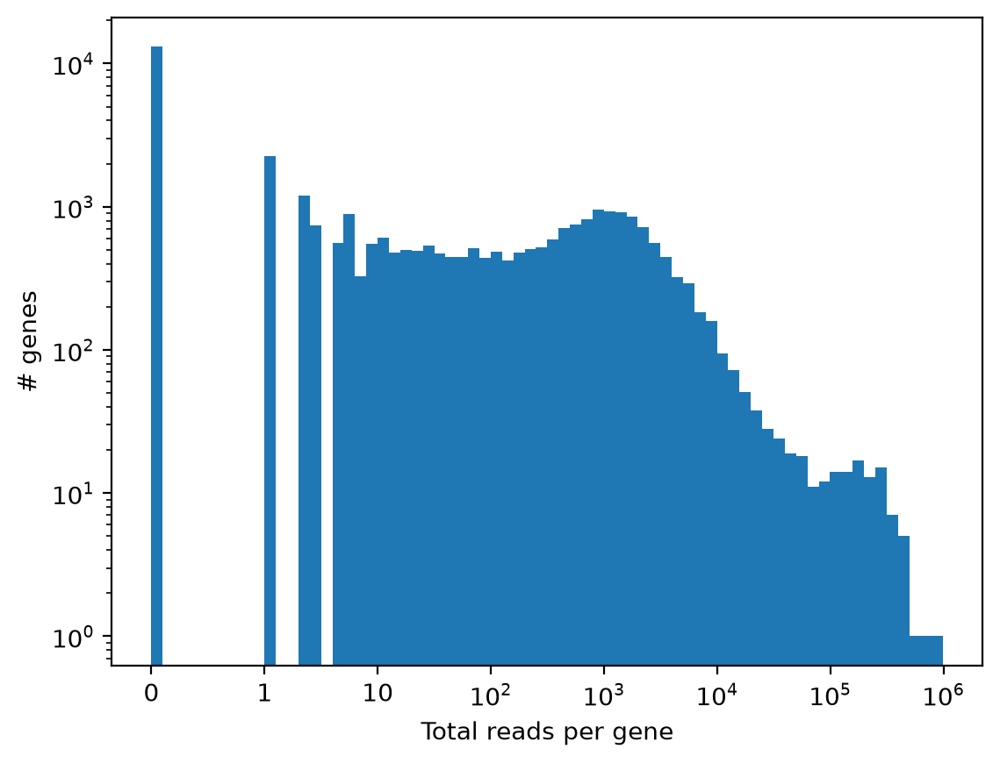

In [454]:
plt.hist(np.log10(pbmcs.X.sum(axis=0).A.flatten() + 0.1), bins = 70);
plt.xticks(ticks = range(-1, 7), labels = ['0', '1', '10'] + [rf"$10^{i}$" for i in range(2,7)]);
plt.semilogy()
plt.xlabel('Total reads per gene')
plt.ylabel('# genes');

Let's do the same thing but now with the number of reads per cell:

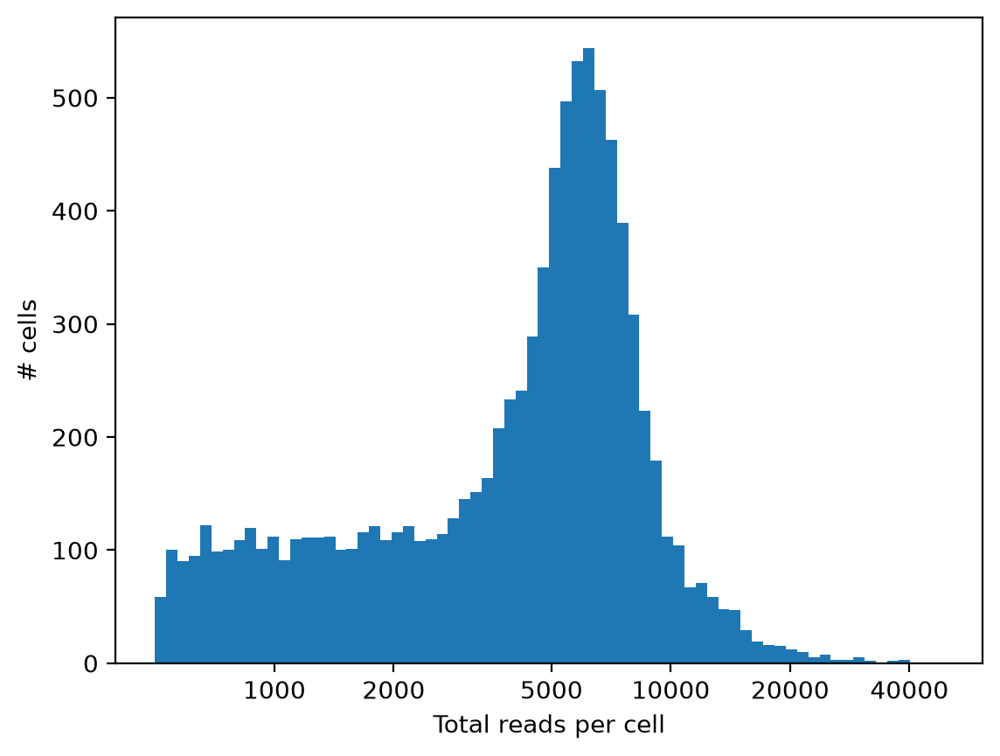

In [455]:
plt.hist(np.log10(pbmcs.X.sum(axis=1).A.flatten() + 0.1), bins = 70);
xticks = [1000, 2000, 5000, 10000, 20000, 40000]
plt.xticks(ticks=np.log10(xticks), labels = xticks)
plt.xlabel('Total reads per cell')
plt.ylabel('# cells');

**Fixing the unique variable names problem from earlier.** You might remember the warning we got when we first loaded the data into Scanpy: something about non-unique (duplicated) variable (gene) names. Let's investigate:

In [456]:
dups = pbmcs.var.index.duplicated(keep=False)
pbmcs.var[dups]

,gene_ids,feature_types,genome
TBCE,ENSG00000285053,Gene Expression,GRCh38
TBCE,ENSG00000284770,Gene Expression,GRCh38
LINC01238,ENSG00000237940,Gene Expression,GRCh38
LINC01238,ENSG00000261186,Gene Expression,GRCh38
CYB561D2,ENSG00000114395,Gene Expression,GRCh38
CYB561D2,ENSG00000271858,Gene Expression,GRCh38
MATR3,ENSG00000280987,Gene Expression,GRCh38
MATR3,ENSG00000015479,Gene Expression,GRCh38
LINC01505,ENSG00000234323,Gene Expression,GRCh38
LINC01505,ENSG00000234229,Gene Expression,GRCh38


Duplicated gene names — but different Ensembl ENSG gene ids! This can happen for many, usually historical or structural reasons. In the case of TBCE, what was thought to be one gene at first turned out to be a readthrough transcript of two genes that follow one another in the genome. In any case, no need to dig too deep, Scanpy's warning tells us exactly what to do in this situation:

In [457]:
pbmcs.var_names_make_unique()

Now let's look at the old duplicates:

In [471]:
pbmcs.var[dups]

,gene_ids,mito,ribo,hemo,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
TBCE,ENSG00000285053,False,False,False,134,0.015227,0.015113,98.573102,143.0,4.969813
TBCE-1,ENSG00000284770,False,False,False,93,0.010010,0.009960,99.009690,94.0,4.553877
LINC01238,ENSG00000237940,False,False,False,49,0.005324,0.005310,99.478224,50.0,3.931826
LINC01238-1,ENSG00000261186,False,False,False,16,0.001704,0.001702,99.829624,16.0,2.833213
CYB561D2,ENSG00000114395,False,False,False,1735,0.216484,0.195965,81.524864,2033.0,7.617760
CYB561D2-1,ENSG00000271858,False,False,False,637,0.072836,0.070305,93.216910,684.0,6.529419
MATR3,ENSG00000280987,False,False,False,26,0.002769,0.002765,99.723139,26.0,3.295837
MATR3-1,ENSG00000015479,False,False,False,1453,0.178256,0.164035,84.527739,1674.0,7.423568
LINC01505,ENSG00000234323,False,False,False,5,0.000532,0.000532,99.946758,5.0,1.791759
LINC01505-1,ENSG00000234229,False,False,False,0,0.000000,0.000000,100.000000,0.0,0.000000


It just added an extra `"-1"` to the duplicates!

### Subsetting AnnData

AnnData is designed in a way very similar to Pandas (some of its structures are literally Pandas DataFrames). Thus, subsetting AnnData is as intuitive as it is with Pandas DataFrames. There are at least three ways to subset AnnData:
* Using `var/obs_names`:

In [306]:
pbmcs['cell_100', 'CD4']

View of AnnData object with n_obs × n_vars = 1 × 1
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

In [320]:
pbmcs[['cell_0', 'cell_1']]

View of AnnData object with n_obs × n_vars = 2 × 36601
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

In [330]:
pbmcs[:, ['CD4', 'CD5']]

View of AnnData object with n_obs × n_vars = 9391 × 2
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

In [331]:
pbmcs[['cell_0', 'cell_1'], ['CD4', 'CD5']]

View of AnnData object with n_obs × n_vars = 2 × 2
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

* Using boolean arrays (just make sure the lengths and dimensions match):

In [332]:
dups

array([False, False, False, ..., False, False, False])

In [334]:
pbmcs[:, dups]

View of AnnData object with n_obs × n_vars = 9391 × 20
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

* Using integer indexes:

In [335]:
pbmcs[1:20, 1:20]

View of AnnData object with n_obs × n_vars = 19 × 19
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

In [339]:
pbmcs[10:20, 10:20].X.toarray()

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

**Subsetting using metadata:** since we can subset with boolean arrays, we can also subset with boolean arrays based on metadata comparisons:

In [354]:
pbmcs.obs.barcode.str.startswith('AAA')

cell_id
cell_0        True
cell_1        True
cell_2        True
cell_3        True
cell_4        True
             ...  
cell_9386    False
cell_9387    False
cell_9388    False
cell_9389    False
cell_9390    False
Name: barcode, Length: 9391, dtype: bool

In [353]:
pbmcs[pbmcs.obs.barcode.str.startswith('AAA')]

View of AnnData object with n_obs × n_vars = 116 × 36601
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

Of course, when subsetting based on variables (genes) metatdata, which is the columns, make sure to subset to place the boolean array in the columns (second) position of the indexer.

In [357]:
pbmcs[:, pbmcs.var.index.str.startswith('MT-')]

View of AnnData object with n_obs × n_vars = 9391 × 13
    obs: 'barcode'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

## Quality control 

Once our data is loaded, we need to control its quality. That is, we need to remove "bad" cells and "bad" genes because they may interfere with our analysis. There are many ways to define "bad" cells and genes. In this workshop, we will focus mostly on filtering out low quality cells. 

Regarding filtering out bad genes, removing non-detected genes (with 0 total counts) should be enough for now. Importantly, QC is not always a straightforward process. Different experiments and batches may require different QC approaches, and the process often becomes iterative, as in going back and forth between QC and some basic downstream analysis. 

There are many helpful resources to learn more about scRNA seq QC. This section of the workshop was inspired by the [Single-cell Best Practices](https://www.sc-best-practices.org/preprocessing-visualization/quality-control/#preprocessing-visualization-quality-control-key-takeaway-1) online book, a [10x Genomics analysis guide](https://www.10xgenomics.com/analysis-guides/common-considerations-for-quality-control-filters-for-single-cell-rna-seq-data), and a chapter from [Basics of Single-Cell Analysis with Bioconductor](https://bioconductor.org/books/3.13/OSCA.basic/quality-control.html#quality-control-motivation), another online book. 

#### Filtering low-quality cells (and droplets)

Low quality cells/droplets can include the following:
* **Empty droplets with no cells:** these usually have very low counts. Looking at the count-per-cell histogram above, we see the minimum number of counts is 500, meaning that low-quality droplets were already removed from this data set (by CellRanger, which produced the files we are using in this case).
* **Damaged or dying cells:** these will have much lower gene counts than healthy cells and can be identified by looking at the distributions of total counts and the number of expressed genes in each cell. Another useful statistic to include is the percentage of reads from mitochondrial genes. Damaged and dying cells usually leak their mitochondrial contents into the cytoplasm, and that includes mitochondrial mRNA. Usually, cells with above 10% mitochondrial mRNAs are discarded.
* **Doublets:** sometimes, a droplet can be loaded with two cells instead of only one, and these doublets can pass for a new cell type. To avoid this scenario, doublets are estimated and removed by libraries like Scrublet (which is implemented in Scanpy) and Cellblender.

Here is a useful visual aid from Single-cell Best Practices:

<center><img src="https://www.sc-best-practices.org/build/quality_control-296960517f0ffeacba25e4230407b920.jpeg"></center>

**Ambient RNA removal:** ambient mRNA that leaked out of damaged cells may end up contaminating good-quality droplets. There are many libraries that aim to correct for this contamination. SoupX, for instance, analyzes both the filtered and raw droplet-by-gene counts data to find the contamination profile before removing it from the data. This step of QC is not always included in the analysis, but can be very useful depending on the experiment.

Performing QC includes calculating metrics and visualizing them to inspect their distributions and determine appropriate cutoffs. Scanpy offers a very convenient, one-stop-shop way to calculate QC meterics: `calculate_qc_metrics()` ([docs here](https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.calculate_qc_metrics.html)). This function calculates useful metrics for both genes and cells. Moreover, it can calculate cell metrics derived from pre-defined groups of genes. This is especially useful to look at the mitochondrial mRNA fraction, as well as the hemoglobin and ribosomal fractions, which can also be used as proxies for quality. To pre-define useful groups of genes, we simply create a new boolean column per group in the `var` (genes) table, where each bool represents whether a gene is included in the group. Scanpy's `calculate_qc_metrics()` calls these groups `qc_vars`.

In [459]:
# mitochondrial genes
pbmcs.var["mito"] = pbmcs.var_names.str.startswith("MT-")

# ribosomal genes
pbmcs.var["ribo"] = pbmcs.var_names.str.startswith(("RPS", "RPL"))

# hemoglobin genes
pbmcs.var["hemo"] = pbmcs.var_names.str.contains("^HB[^(P)]")

Then we can check what genes are included in each group:

In [460]:
pbmcs.var[pbmcs.var['mito']]

,gene_ids,feature_types,genome,mito,ribo,hemo
MT-ND1,ENSG00000198888,Gene Expression,GRCh38,True,False,False
MT-ND2,ENSG00000198763,Gene Expression,GRCh38,True,False,False
MT-CO1,ENSG00000198804,Gene Expression,GRCh38,True,False,False
MT-CO2,ENSG00000198712,Gene Expression,GRCh38,True,False,False
MT-ATP8,ENSG00000228253,Gene Expression,GRCh38,True,False,False
MT-ATP6,ENSG00000198899,Gene Expression,GRCh38,True,False,False
MT-CO3,ENSG00000198938,Gene Expression,GRCh38,True,False,False
MT-ND3,ENSG00000198840,Gene Expression,GRCh38,True,False,False
MT-ND4L,ENSG00000212907,Gene Expression,GRCh38,True,False,False
MT-ND4,ENSG00000198886,Gene Expression,GRCh38,True,False,False


Now we can use `calculate_qc_metrics` (we can also call it without setting up our `qc_vars`, as that step is optional). Below is the list of metrics it calculates. Log1p is the "log-1-plus": $\text{log1p}(x) = \log(x + 1)$. Taking the log is a very common operation to "shrink" the range of the data so extremely large values are visually closer to smaller values; it can also be useful for other downstream analyses. (The "plus-1" part is because $\log(0)=-\infty$, so adding 1 makes it $log(1)=0$.)

| Metrics | Description | log1p calculated |
| --- | --- | ---|
| **Cell-level** |
| `n_genes_by_counts` | Number of genes with positive (non-zero) counts in a cell | Yes|
| `total_counts` | Total number of counts in a cell | Yes |
| `pc_counts_in_top_{n}_genes` | Cumulative percentage of counts for the $n$ highest expressed genes in a cell, this is useful to estimate library complexity (less "complex" cells with have fewer highly-expressed genes)  |
| `total_counts_{qc_var}` | Total number of counts for each variable in `qc_vars` (i.e. mitochondrial genes)| Yes |
| `pct_counts_{qc_var}` | Percentage of total counts for a cell which are in `qc_vars` | Yes |
| **Gene-level** |
| `total_counts` | Sum of counts for a gene | Yes |
| `mean_counts` | Mean expression over all cells | Yes |
| `n_cell_by_counts` | Number of cells with at least 1 count for this gene |
| `pct_droupout_by_counts` | Percentage of cells with 0 counts for this gene |

Now, we are ready to calculate QC metrics:

In [461]:
sc.pp.calculate_qc_metrics(
    pbmcs, 
    qc_vars = ['mito', 'ribo', 'hemo'],
    inplace=True
)

Let's check out all the metadata that's been added:

In [468]:
pbmcs

AnnData object with n_obs × n_vars = 9391 × 36601
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hemo', 'log1p_total_counts_hemo', 'pct_counts_hemo'
    var: 'gene_ids', 'feature_types', 'genome', 'mito', 'ribo', 'hemo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

In [472]:
pbmcs.var

,gene_ids,mito,ribo,hemo,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
MIR1302-2HG,ENSG00000243485,False,False,False,1,0.000106,0.000106,99.989352,1.0,0.693147
FAM138A,ENSG00000237613,False,False,False,0,0.000000,0.000000,100.000000,0.0,0.000000
OR4F5,ENSG00000186092,False,False,False,0,0.000000,0.000000,100.000000,0.0,0.000000
AL627309.1,ENSG00000238009,False,False,False,10,0.001065,0.001064,99.893515,10.0,2.397895
AL627309.3,ENSG00000239945,False,False,False,0,0.000000,0.000000,100.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...
AC141272.1,ENSG00000277836,False,False,False,1,0.001810,0.001809,99.989352,17.0,2.890372
AC023491.2,ENSG00000278633,False,False,False,0,0.000000,0.000000,100.000000,0.0,0.000000
AC007325.1,ENSG00000276017,False,False,False,6,0.000639,0.000639,99.936109,6.0,1.945910
AC007325.4,ENSG00000278817,False,False,False,9,0.000958,0.000958,99.904164,9.0,2.302585


In [469]:
pbmcs.obs

,barcode,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mito,log1p_total_counts_mito,pct_counts_mito,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hemo,log1p_total_counts_hemo,pct_counts_hemo
cell_id,,,,,,,,,,,,,,,,,,
cell_0,AAACCTGAGACTTTCG-1,1300,7.170888,3467.0,8.151334,42.774733,55.581194,64.464955,76.925296,326.0,5.789960,9.402942,1220.0,7.107426,35.188927,0.0,0.000000,0.000000
cell_1,AAACCTGAGATCGGGT-1,322,5.777652,542.0,6.297109,49.815498,59.040590,77.490775,100.000000,132.0,4.890349,24.354244,35.0,3.583519,6.457564,0.0,0.000000,0.000000
cell_2,AAACCTGAGGCGACAT-1,2000,7.601402,5261.0,8.568267,33.567763,45.523665,56.034974,69.397453,351.0,5.863631,6.671736,1470.0,7.293698,27.941456,1.0,0.693147,0.019008
cell_3,AAACCTGAGTCAATAG-1,363,5.897154,679.0,6.522093,53.166421,61.266568,75.994109,100.000000,226.0,5.424950,33.284241,7.0,2.079442,1.030928,0.0,0.000000,0.000000
cell_4,AAACCTGAGTTGTAGA-1,409,6.016157,710.0,6.566672,49.295775,56.478873,70.563380,100.000000,219.0,5.393628,30.845070,23.0,3.178054,3.239436,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cell_9386,TTTGTCATCAGCCTAA-1,2595,7.861727,7581.0,8.933533,32.014246,44.453238,54.267247,67.101965,583.0,6.369901,7.690279,1874.0,7.536364,24.719694,0.0,0.000000,0.000000
cell_9387,TTTGTCATCGACGGAA-1,2211,7.701652,6232.0,8.737613,33.231707,45.795892,56.241977,68.966624,252.0,5.533390,4.043646,1779.0,7.484369,28.546215,0.0,0.000000,0.000000
cell_9388,TTTGTCATCGGAAACG-1,1640,7.403061,4513.0,8.414939,38.754709,51.296255,60.713494,74.739641,136.0,4.919981,3.013517,1657.0,7.413367,36.716156,0.0,0.000000,0.000000


In [365]:
pbmcs.obs

,barcode,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
cell_id,,,,,,,,,
cell_0,AAACCTGAGACTTTCG-1,1300,7.170888,3467.0,8.151334,42.774733,55.581194,64.464955,76.925296
cell_1,AAACCTGAGATCGGGT-1,322,5.777652,542.0,6.297109,49.815498,59.040590,77.490775,100.000000
cell_2,AAACCTGAGGCGACAT-1,2000,7.601402,5261.0,8.568267,33.567763,45.523665,56.034974,69.397453
cell_3,AAACCTGAGTCAATAG-1,363,5.897154,679.0,6.522093,53.166421,61.266568,75.994109,100.000000
cell_4,AAACCTGAGTTGTAGA-1,409,6.016157,710.0,6.566672,49.295775,56.478873,70.563380,100.000000
...,...,...,...,...,...,...,...,...,...
cell_9386,TTTGTCATCAGCCTAA-1,2595,7.861727,7581.0,8.933533,32.014246,44.453238,54.267247,67.101965
cell_9387,TTTGTCATCGACGGAA-1,2211,7.701652,6232.0,8.737613,33.231707,45.795892,56.241977,68.966624
cell_9388,TTTGTCATCGGAAACG-1,1640,7.403061,4513.0,8.414939,38.754709,51.296255,60.713494,74.739641


Scanpy contains 3 submodules: `pp` for preprocessing, `pl` for plotting, and `tl` for tools. Documentation for each sublibrary can be found [here](https://scanpy.readthedocs.io/en/stable/api/preprocessing.html), [here](https://scanpy.readthedocs.io/en/stable/api/plotting.html), and [here](https://scanpy.readthedocs.io/en/stable/api/tools.html). The plotting library is based on Matplolib and Seaborn, which makes it very intuitive to use. Let's plot a few distributions:

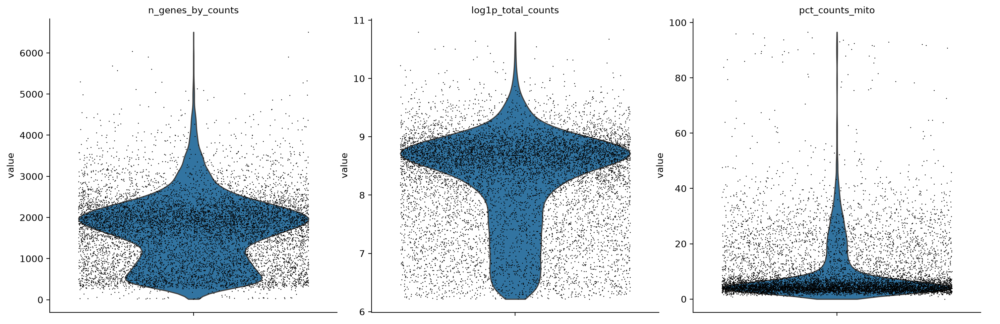

In [477]:
sc.pl.violin(
    pbmcs,
    ["n_genes_by_counts", "log1p_total_counts", "pct_counts_mito"],
    jitter=0.4,
    multi_panel=True,
)

It is always very helpful to plot these features together (i.e. on a scatter plot):

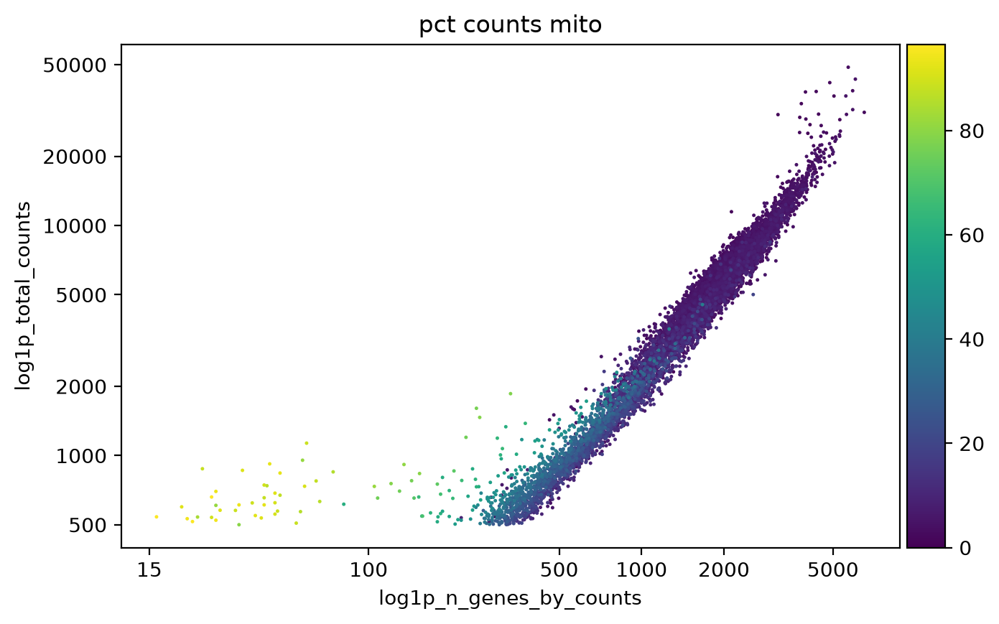

In [510]:
ax = sc.pl.scatter(pbmcs, x='log1p_n_genes_by_counts', y='log1p_total_counts', color='pct_counts_mito', show=False)
xticks = [15, 100, 500, 1000, 2000, 5000]
yticks = [500, 1000, 2000, 5000, 10000, 20000, 50000]
ax.set_xticks(ticks=np.log1p(xticks), labels =xticks);
ax.set_yticks(ticks=np.log1p(yticks), labels =yticks);

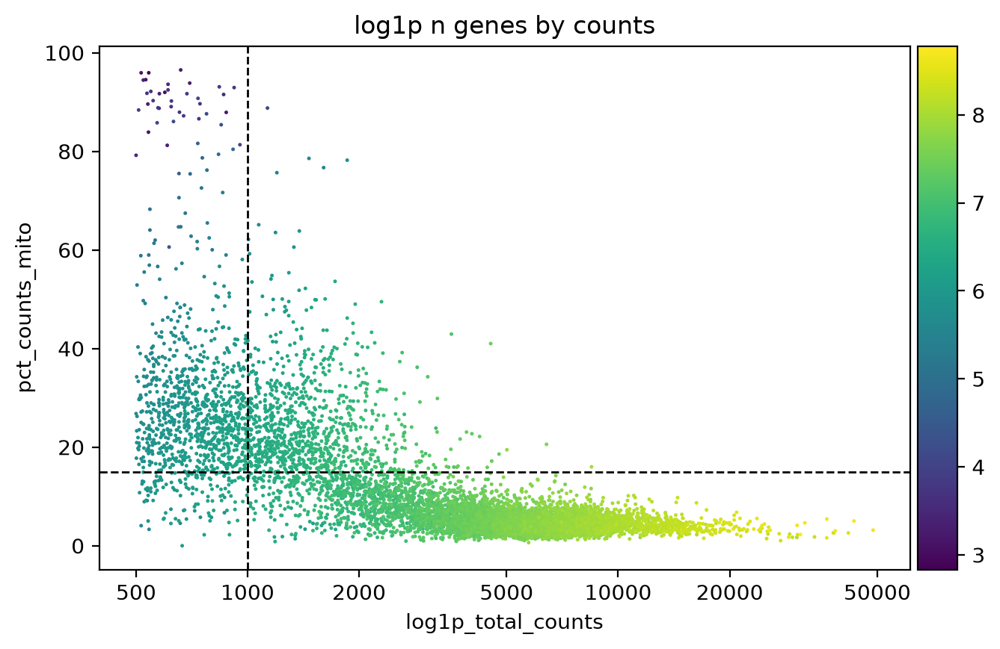

In [570]:
ax = sc.pl.scatter(pbmcs, x='log1p_total_counts', y='pct_counts_mito', color='log1p_n_genes_by_counts', show=False)
ax.axhline(15, c='k', ls='dashed', lw=1);
ax.axvline(np.log1p(1000), c='k', ls='dashed', lw=1);
xticks = [500, 1000, 2000, 5000, 10000, 20000, 50000]
ax.set_xticks(ticks=np.log1p(xticks), labels =xticks);

There are two main methods to set a threshold: (1) by visual inspection of the distribution, which can be subjective, or (2) using the median absolute deviation, $\text{MAD} = \text{median}(X_i - \text{median(X)})$, and excluding cells that are beyond 3 MADs away from the median. For simplicity's sake, let's set the thresholds manually. It is always recommended to start with permissive thresholds first and then come back after some initial downstream analysis has been done to see the effect of narrower thresholding on the results. For now, let's select cells with more than 1000 total reads and less than 10% mitochondrial mRNA fraction.

In [600]:
pbmcs_qc = pbmcs[(pbmcs.obs.pct_counts_mito < 15) & (pbmcs.obs.total_counts > 1000)].copy()
pbmcs_qc

AnnData object with n_obs × n_vars = 7409 × 36601
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hemo', 'log1p_total_counts_hemo', 'pct_counts_hemo'
    var: 'gene_ids', 'mito', 'ribo', 'hemo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

Let's also remove genes with 3 or fewer counts:

In [601]:
pbmcs_qc = pbmcs_qc[:, pbmcs_qc.var.total_counts > 3].copy()
pbmcs_qc

AnnData object with n_obs × n_vars = 7409 × 19310
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hemo', 'log1p_total_counts_hemo', 'pct_counts_hemo'
    var: 'gene_ids', 'mito', 'ribo', 'hemo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

Now we are left with 7,409 cells and 19,310 genes!
 
Let's now get rid of the doublets with Scanpy's implementation of Scrublet (paper [here](https://pubmed.ncbi.nlm.nih.gov/30954476/)), `sc.pp.scrublet()`. Scrublet simulates doublets based on existing cells and scores the resemblance of each droplet to these simulated doublets. Running this command should take about a minute.

In [602]:
sc.pp.scrublet(pbmcs_qc)

Done! Scrublet's results are essentially two columns appended to `obs`: `doublet_score` and `predicted_doublet`, the latter of which is simply a bool column indicating whether a cell is predicted to be a doublet or not.

In [603]:
pbmcs_qc

AnnData object with n_obs × n_vars = 7409 × 19310
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hemo', 'log1p_total_counts_hemo', 'pct_counts_hemo', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'mito', 'ribo', 'hemo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)

In [604]:
pbmcs_qc.obs[['doublet_score', 'predicted_doublet']]

,doublet_score,predicted_doublet
cell_id,,
cell_0,0.032060,False
cell_2,0.039643,False
cell_6,0.056487,False
cell_7,0.018121,False
cell_9,0.033036,False
...,...,...
cell_9386,0.026025,False
cell_9387,0.064935,False
cell_9388,0.096066,False


In [605]:
pbmcs_qc.obs.predicted_doublet.sum()

np.int64(0)

So there are no predicted doublets! Wow!

## Normalization

Just as we saw with bulk RNA sequencing analysis, single-cell RNA seq data needs to be normalized. As we saw earlier, the number of counts per cell can range from 1,000 to 25,000. This makes it very hard to compare cells, thus introducing significant biases in downstream analysis. As with bulk RNA seq, there are many normalization methods, each with its own set of assumptions. The most common one by far is counts-per-million (CPM), in which we divide each count for gene $g$ in cell $c$, $X_{gc}$, by the total counts in its cell and multiply it by $10^6$, making all library sizes exactly $10^6$:
$$\text{CPM}_{gc}= \frac{X_{gc}}{\sum_{g'}X_{g'c}} \times 10^6$$

Many analyses require going a step further and taking the logarithm of the CPMs: this not only makes the data much easier to visualize, but it also stabilizes the variance, a property useful to many settings:

$$X'_{gc} = \log\left(\frac{X_{gc}}{\sum_{g'}X_{g'c}} + \alpha\right)$$

Where $\alpha$ is a pseudocount to ensure we are not taking the logarithm of 0. Scanpy offers a very convenient function that calculates the CPMs (without taking the log):

In [675]:
norm = sc.pp.normalize_total(
    adata = pbmcs_qc,
    target_sum = 1e6,
    inplace = False
)
norm

{'X': <Compressed Sparse Row sparse matrix of dtype 'float32'
 	with 14591684 stored elements and shape (7409, 19310)>,
 'norm_factor': array([0.003467, 0.005261, 0.004462, ..., 0.004513, 0.007511, 0.004549],
       dtype=float32)}

In [676]:
norm['X'].sum(1)

matrix([[ 999999.94],
        [1000000.06],
        [1000000.  ],
        ...,
        [ 999999.94],
        [1000000.  ],
        [ 999999.94]], dtype=float32)

The `X` returned is the normalized version of the original data, and the `norm_factor` array is simply the total counts divided by $10^6$. Now we should expect the rows to sum up to 1:

Let's keep the normalized data as a layer in our AnnData:

In [677]:
pbmcs_qc.layers['cpm'] = norm['X'].copy()
pbmcs_qc

AnnData object with n_obs × n_vars = 7409 × 19310
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hemo', 'log1p_total_counts_hemo', 'pct_counts_hemo', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'mito', 'ribo', 'hemo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X), 'cpm', 'log1p_cpm'

Let's also create another layer that is the log-CPM:

In [682]:
pbmcs_qc.layers['log1p_cpm'] = sc.pp.log1p(norm['X'], base=10, copy=True)
pbmcs_qc.layers

Layers with keys: None, 'cpm', 'log1p_cpm'

Let's plot histograms of all 14,591,684 non-zero gene count values in each layer of our AnnData to see the effect of noramlization:

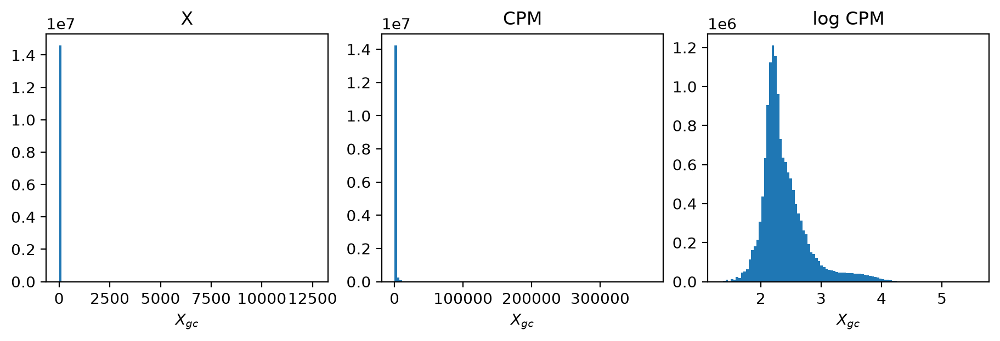

In [696]:
fig, axs = plt.subplots(1,3, layout='constrained', figsize=(9,3))
ax = axs[0]
ax.hist(pbmcs_qc.X.data, bins=100)
ax.set_xlabel(r'$X_{gc}$')
ax.set_title('X')
ax = axs[1]
ax.hist(pbmcs_qc.layers['cpm'].data, bins=100)
ax.set_xlabel(r'$X_{gc}$')
ax.set_title('CPM')
ax = axs[2]
ax.hist(pbmcs_qc.layers['log1p_cpm'].data, bins=100)
ax.set_xlabel(r'$X_{gc}$')
ax.set_title('log CPM');

Clearly, without taking the logarithm, extreme values easily overtake the data and make all other data points look infinitesimal in comparison. However, taking the log (no matter the base) somehow groups everything together, dramatically reduces the hegemony of extreme values, and gives the distribution a much more meanigul shape. A PCA or UMAP of the first two layers would put all the cells together in one tiny cluster, while the log CPM would allow for much better cluster separation. 

As mentioned earlier, there are other normalization methods, but this one works very well and is very popular. Other popular methods include Scran and SCTransform, both of which are much fancier than CPM and may be better in certain scenarios. 10x Genomics has a useful guide [here](https://www.10xgenomics.com/analysis-guides/single-cell-rna-seq-data-normalization).

## Highly variable gene selection

In general, most genes in an scRNA seq data set will not be very useful at differentiating between different cell types, such as housekeeping genes and shared lineage genes. However, despite not being useful, their noise contributes to the general noise in the data set and can decrease the signal-to-noise ratio, thus weakening and distorting the results of downstream analyses. Therefore, we want to keep the informative genes and discard the uninformative ones.

One way to approximate which genes are important and which should be discarded is to only keep the most highly variable genes. Because they are highly variable, we assume that part of their variability is biologically relevant; this means that they vary across different cell types and are thus useful in terms of differentiating those cell types from one another.

Estimating variability in this context is unfortunately not as straightforward as simply calculating per-gene variance and picking the top 2000 genes. This is because there exists a relationship between the mean and variance of expression: the greater the mean, the greater the variance. Consequently, selecting the top 2000 genes by variance would likely mean selecting the top highest expressed genes. 

We can verify this ourselves, visually. First, let's code a helper function to calculate variances:

In [834]:
def calculate_csr_vars(mat, axis=0):
    '''
    Since SciPy's CSR matrix doesn't have a native variance function,
    we have to do it manually using the useful relation:
    Var(X) = E[X^2] - E[X]^2
    '''
    return (mat.power(2).mean(axis=axis) - np.power(mat.mean(axis=axis), 2)).A.flatten()

Then calculate the means and the variances of both non-normalized and CPM data:

In [837]:
x_means, x_vars = pbmcs_qc.X.mean(0).A.flatten(), calculate_csr_vars(pbmcs_qc.X)
cpm_means, cpm_vars = pbmcs_qc.layers['cpm'].mean(0).A.flatten(), calculate_csr_vars(pbmcs_qc.layers['cpm'])

Now let's plot:

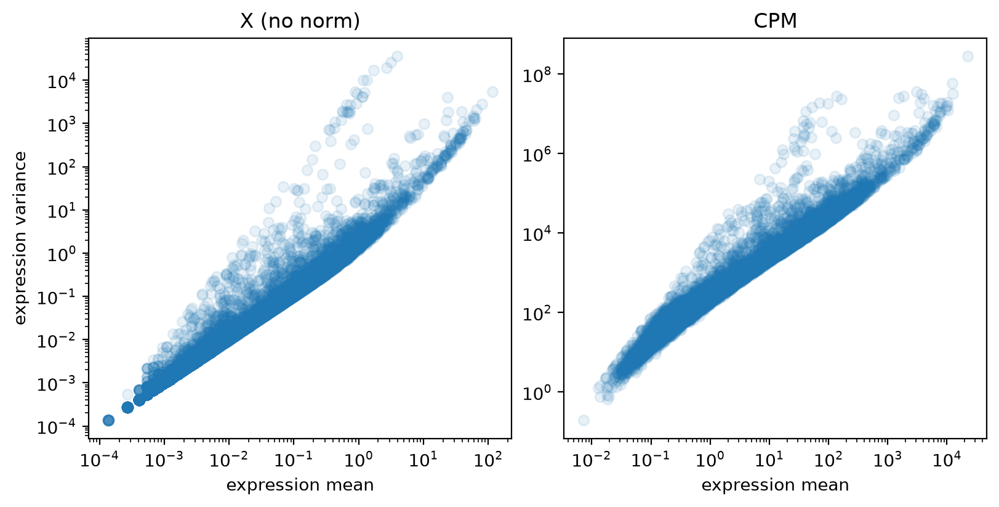

In [840]:
fig, axs = plt.subplots(1,2, layout='constrained', figsize=(8,4))
ax = axs[0]
ax.scatter(x_means, x_vars, alpha=0.1)
ax.loglog()
ax.set(title='X (no norm)', xlabel='expression mean', ylabel='expression variance')
ax = axs[1]
ax.scatter(cpm_means, cpm_vars, alpha=0.1)
ax.loglog()
ax.set(title='CPM', xlabel='expression mean');

See how the variance is almost perfectly positively correlated with the mean expression! Also, see how some genes seem to have higher variance for their mean expression? These are exactly the highly variable genes we want to select!

Current algorithms (at least the ones offered by Scanpy) use exactly this observation. They assume that most genes are un-informative in terms of differentiating cell types, model the mean-variance relationship with a curve to get the expected variance for each gene, and then select the genes that have higher variance than expected. The hope is that the extra variance in these genes is due to useful biological variance between the different cell types.

All this may sound a little complicated, but with Scanpy it is very easy:

In [845]:
sc.pp.highly_variable_genes(
    adata = pbmcs_qc, 
    layer = 'log1p_cpm', 
    n_top_genes = 2000, # 2000 genes is standard
    flavor = 'seurat', 
    n_bins = 30,
    inplace = True
)

In [842]:
pbmcs_qc

AnnData object with n_obs × n_vars = 7409 × 19310
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hemo', 'log1p_total_counts_hemo', 'pct_counts_hemo', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'mito', 'ribo', 'hemo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'cpm', 'log1p_cpm'

Notice the `var`-level (gene-level) columns it added: `means`, `dispersions`, `dispersion_norm`, and `highly_variable`. The term dispersion is used because the Seurat algorithm fits a Negative Binomial, and the dispersion is a term in the variance-mean relationship.

In [843]:
pbmcs_qc.var[['highly_variable', 'means', 'dispersions', 'dispersions_norm']]

,highly_variable,means,dispersions,dispersions_norm
AL627309.1,False,0.007844,2.176133,-0.084988
AL627309.5,False,0.055033,2.314460,0.564226
AP006222.2,False,0.002516,1.906024,-1.352704
LINC01409,False,0.336754,2.163333,-0.021796
FAM87B,True,0.011122,2.436771,1.138276
...,...,...,...,...
AC233755.1,True,0.045515,3.504952,6.151610
AC136616.2,True,0.005215,3.656937,6.864927
AC141272.1,True,0.002190,2.787840,2.785962
AC007325.1,False,0.004967,2.298491,0.489277


Scanpy also offers an easy way to plot things:

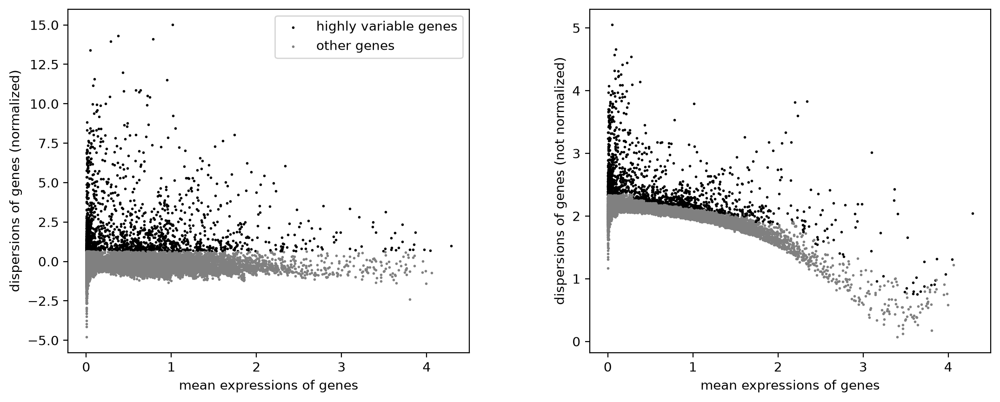

In [844]:
sc.pl.highly_variable_genes(pbmcs_qc)

Focus on the plot on the left. Here, the dispersion-mean relationship is normalized such that non-informative genes have on average 0 dispersiond, making the highly variable ones easier to pick up on. Let's visualize it on our own plots:

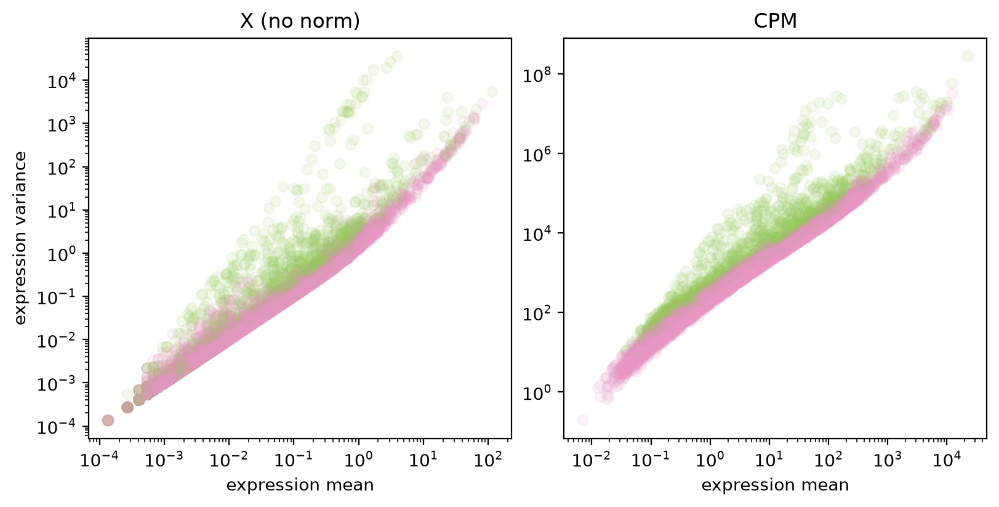

In [852]:
fig, axs = plt.subplots(1,2, layout='constrained', figsize=(8,4))
ax = axs[0]
ax.scatter(x_means, x_vars, alpha=0.1, c=pbmcs_qc.var['highly_variable'], 
           cmap = 'PiYG', vmin=-0.5, vmax=1.5)
ax.loglog()
ax.set(title='X (no norm)', xlabel='expression mean', ylabel='expression variance')
ax = axs[1]
ax.scatter(cpm_means, cpm_vars, alpha=0.1, c=pbmcs_qc.var['highly_variable'], 
           cmap = 'PiYG', vmin=-0.5, vmax=1.5)
ax.loglog()
ax.set(title='CPM', xlabel='expression mean');

## Dimensionality reduction

What we were all waiting for! Almost no scRNA seq data has been analyzed without producing a nice 2D visual map of the cells. The process of going from 2000 dimensions (the 2000 highly variable genes, or HVGs we just selected) to only 2 is called dimensionality reduction.

#### Principal component analysis

Principal component analysis (PCA), which we also covered in the bulk RNA seq workshop, is the bread and butter of dimensionality reduction. PCA is a purely linear algebra method that essentially tries to find a lower-dimensional (e.g. 2D) coordinate space which maximizes the variance of the projections of the data points (to make them look as separate from one another as possible).

With Scanpy, the function `sc.pp.pca()` automatically performs PCA only using the HVGs (but this can be changed with `mask_var`):

In [854]:
sc.pp.pca(
    pbmcs_qc, 
    layer = 'log1p_cpm',
    n_comps = 50,  # default is 50
)

In [855]:
pbmcs_qc

AnnData object with n_obs × n_vars = 7409 × 19310
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hemo', 'log1p_total_counts_hemo', 'pct_counts_hemo', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'mito', 'ribo', 'hemo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'cpm', 'log1p_cpm'

Let's check out the new objects in `obsm` and `varm`:

In [861]:
pbmcs_qc.obsm['X_pca'].shape

(7409, 50)

These are the coordinates of the data in the 50-dimensional space defined by the principal components. While it is 50-dimension, the variance explained by each dimension goes down from left to right. This means plotting just the first two dimensions will give us the maximum separation possible in a 2D space. Let's plot it. 

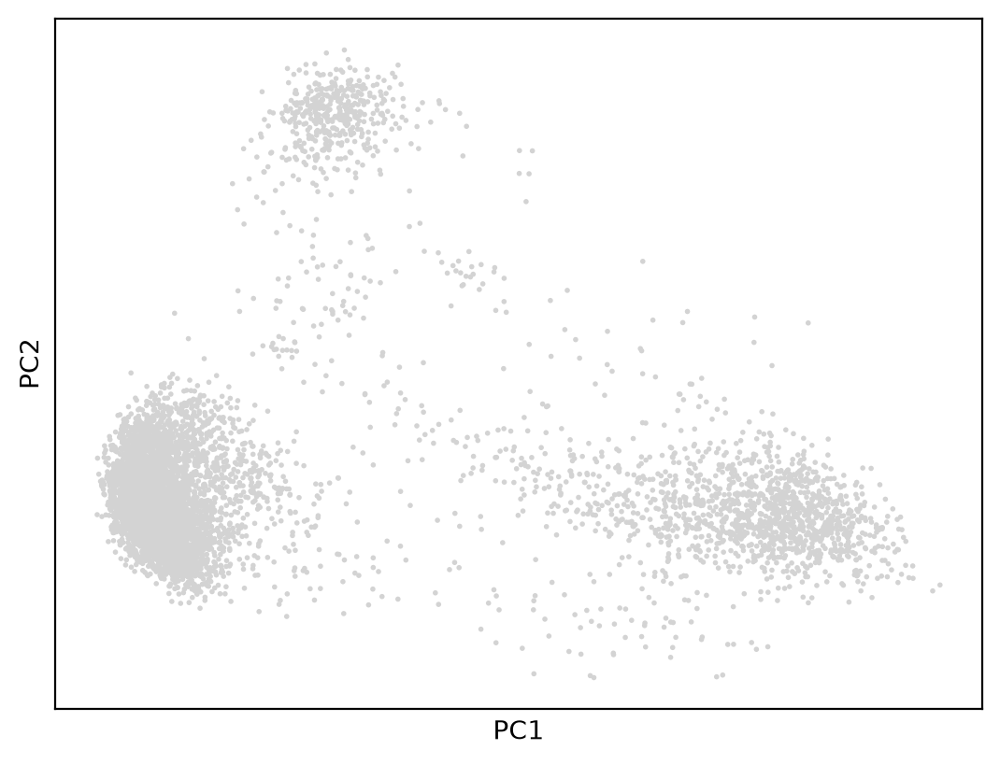

In [869]:
sc.pl.pca(pbmcs_qc)

Beautiful! Scanpy's PCA plotting function `sc.pl.pca()` has lot of functionality. For example, you can plot the expression of genes of interest too! (As always, feel free to explore the [documentation here](https://scanpy.readthedocs.io/en/stable/api/generated/scanpy.pl.pca.html)!)

In [904]:
pbmcs_qc.var.index[pbmcs_qc.var.index.str.contains('NCAM')]

Index(['NCAM1', 'NCAM2'], dtype='str')

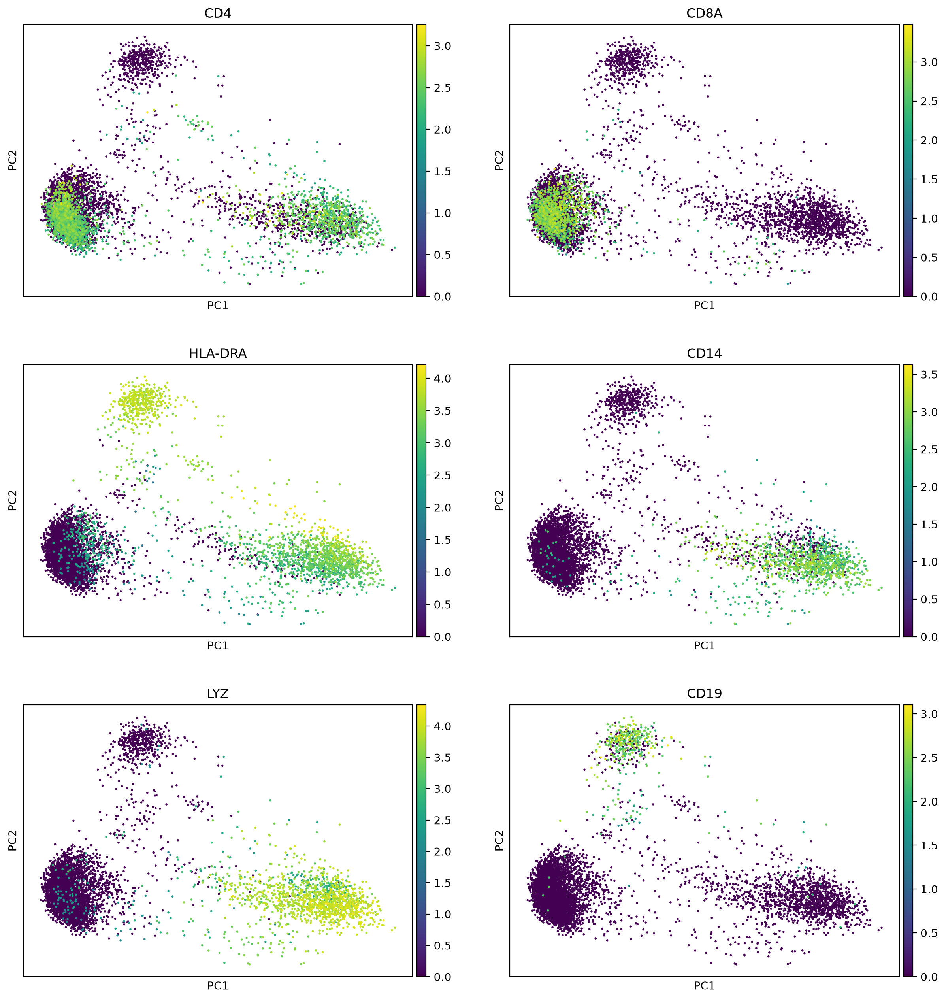

In [913]:
sc.pl.pca(
    pbmcs_qc, 
    color=['CD4', 'CD8A', 'HLA-DRA', 'CD14', 'LYZ', 'CD19'], 
    layer = 'log1p_cpm', 
    ncols=2
)

**PCA as a QC for QC:** This function is also extremely useful as a way to validate your QC. For instance you can color the cells according to their mitochondrial (or hemoglobin, or ribosomal) mRNA fractions. Even more importantly, in case you have different samples or batches (sadly not the case here), you *should* color the cells according to their sample/batch origin and ensure that they are all evenly spread out without clustering (based on sample/batch) into new artificial cell populations.

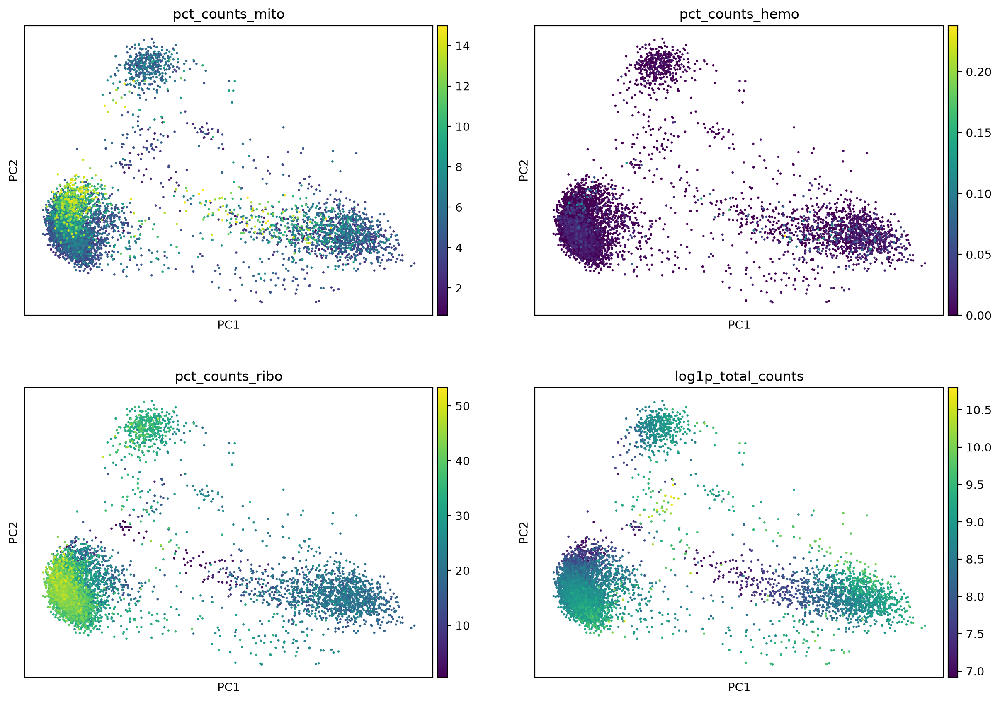

In [919]:
sc.pl.pca(
    pbmcs_qc, 
    color=['pct_counts_mito', 'pct_counts_hemo', 'pct_counts_ribo', 'log1p_total_counts'], 
    layer = 'log1p_cpm', 
    ncols=2
)

As mentioned earlier, PCA aims to maximize the variance of the projections of the data points, so each dimension contains (or explains) some of the total variance of the sample. The variance explained by the first PC (dimension) is highest, and from there it decreases monotonically. Scanpy can plot that for you easily:

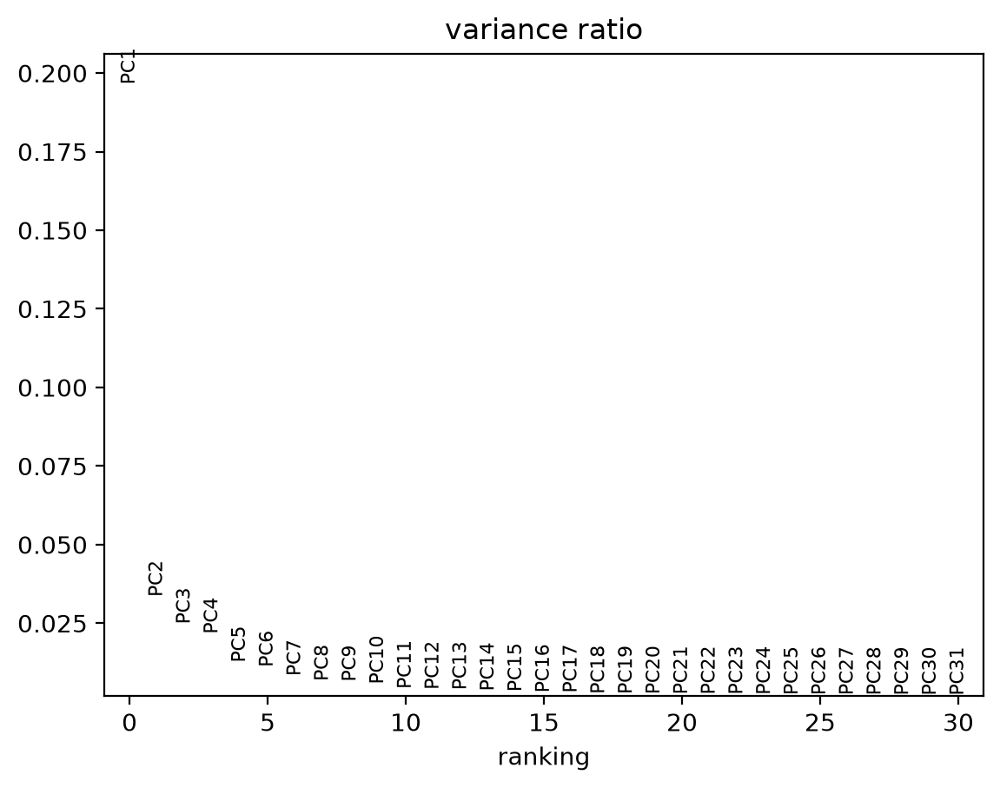

In [907]:
sc.pl.pca_variance_ratio(pbmcs_qc)

Here, we see that the first 11 components explain the most variance, while all the other ones are likely to be random noise. This will serve us well in the next section.

Another object that was computed and saved during PCA is the **PC loadings** matrix in `varm`:

In [909]:
pbmcs_qc.varm['PCs']

array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       ...,
       [ 5.41840836e-06,  1.40401797e-04,  4.47985040e-05, ...,
        -3.77551041e-05, -4.73696768e-04,  3.50414950e-04],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])

It is of dimensions 19310 $\times$ 50 (number of genes, number of components), and it defines the 50 dimensional space PCA optimized by weighing each gene (i.e. each dimension). Scanpy can also plot these loadings to get a sense of which genes contribute the most (positively or negatively) to a PC, i.e., which genes contribute the most to the variance explained by each component. 

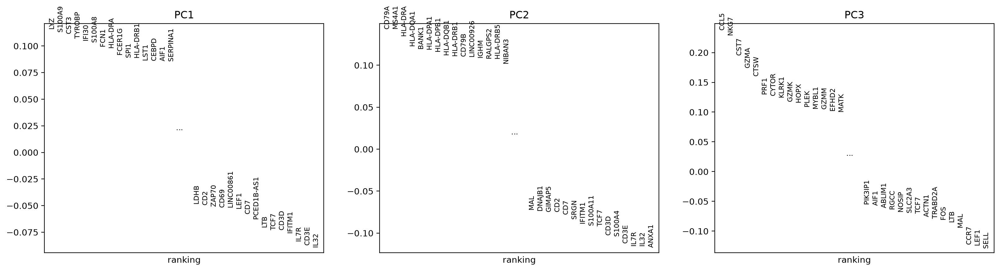

In [910]:
sc.pl.pca_loadings(pbmcs_qc, components = [1,2,3])

Very interesting! It seems like PC1 is primarily based on the lymphoid-myeloid lineage bifurcation, while PCs 2 and 3 are more about distinguishing different lymphoid lineage-derived cells (mainly T and B lymphocytes) from one another.

### UMAP: a nearest neighbor graph method

You probably have heard of UMAP before. UMAP (uniform manifold approximation and projection) is another very popular method for dimensionality reduction. UMAP is very different from PCA. For one, unlike PCA, it is non-linear, which makes it very adaptable to lots of weird data distributions. UMAP understands the structure of high-dimensional data by looking at each data point's nearest neighbors; with a network of nearest neighbors, it is able to infer the topology (i.e. 'shape') of the data distribution. (This makes UMAP a method in the field of topological data analysis.) For a much deeper and more eloquent explanation, check out [the documentation of `umap-learn`](https://umap-learn.readthedocs.io/en/latest/how_umap_works.html), a popular python UMAP library.

Because UMAP is very computationally intensive and sensitive to noise, it is generally applied not to the expression data itself, **but the PCA projections**. This is another reason why PCA is so important, and why it is important to plot the variance explained by each component, so we can choose which components to use and which to discard.

With Scanpy, the first step is to compute the nearest neighbors graph with:

In [923]:
sc.pp.neighbors(pbmcs_qc, use_rep='X_pca', n_pcs=11)

In [1017]:
pbmcs_qc.obsp

PairwiseArrays with keys: 'distances', 'connectivities'

Notice how I specified the number of PCs to use (`n_pcs`) using the variance explained plot above! Try setting this argument to 50 (all the PCs we computed) and see the difference. I tried it, and it looks way better with fewer PCs. This goes to show that less can be more, and quality can be much more important than quantity (at least in this particular case).

The next step is to compute the UMAP coordinates (it should take at least a few seconds, so be patient!):

In [924]:
sc.tl.umap(pbmcs_qc)

Now, let's plot!

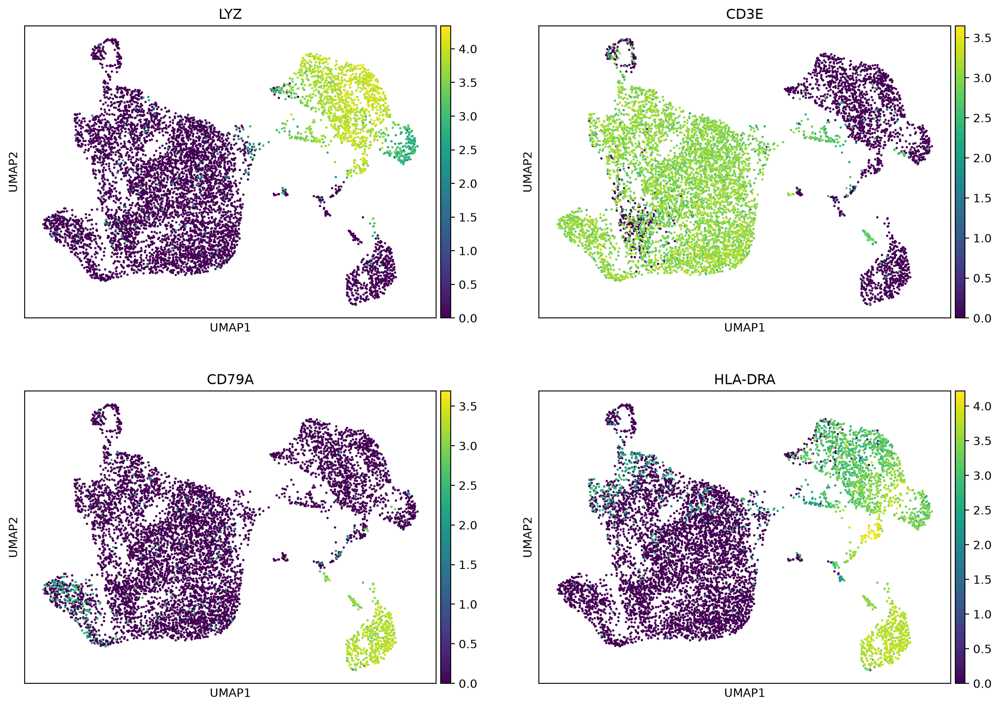

In [930]:
sc.pl.umap(
    pbmcs_qc,
    color = ['LYZ', 'CD3E', 'CD79A', 'HLA-DRA'],
    layer = 'log1p_cpm',
    ncols = 2
)

## Clustering

While we are now able see a 2D representation of our 19,000-dimensional 7,400 cells, it is very hard to visually interpret and distinguish their subpopulations based on a 2D UMAP. Enter clustering: a method to categorize data points into relatively homogeneous clusters (i.e. groups of similar data point). 

There are many clustering algorithms out there, and you might already be familiar with K-nearest neighbors (KNN) or K-means clustering, two very popular methods. While they could be used in this case, it makes very strong assumptions about the distribution of the data that are unlikely to apply to gene expression data.

The common method for scRNA seq is Leiden clustering (named after Leiden University, where it was developed). Leiden clustering is applied to the nearest neighbors graph structure calculated by `sc.pp.neighbors()`. Like most of the functions we've seen, this one comes with lots of dials and buttons. Read [the docs](https://scanpy.readthedocs.io/en/stable/generated/scanpy.tl.leiden.html) before using it!

In [941]:
sc.tl.leiden(pbmcs_qc, flavor="igraph", n_iterations=-1)

Done! Let's look at the clustering:

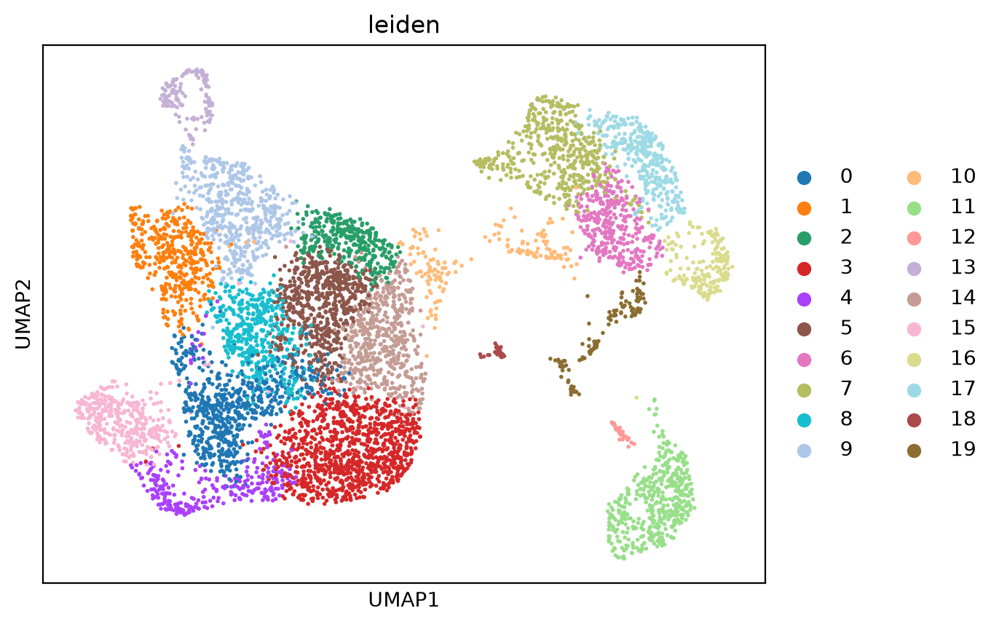

In [942]:
sc.pl.umap(
    pbmcs_qc,
    color = 'leiden',
    layer = 'log1p_cpm',
    ncols = 2
)

Wow! So many clusters! But 20 even the right number of clusters?

The Leiden clustering algorithm has its own internal metrics to potimize the number of clusters, but it also heavily depends on the resolution parameter. We can easily change that `resolution` parameter in the `sc.tl.leiden()` function and see how it affects clustering:

In [958]:
resoluts = [0.02, 0.25, 0.5, 0.75, 1, 1.5, 1.75, 2.0]
for res in resoluts:
    sc.tl.leiden(
        pbmcs_qc, 
        key_added=f"leiden_res_{res}", # to keep track of clusters for each res 
        resolution=res, 
        flavor="igraph"
    )

Now let's plot them!

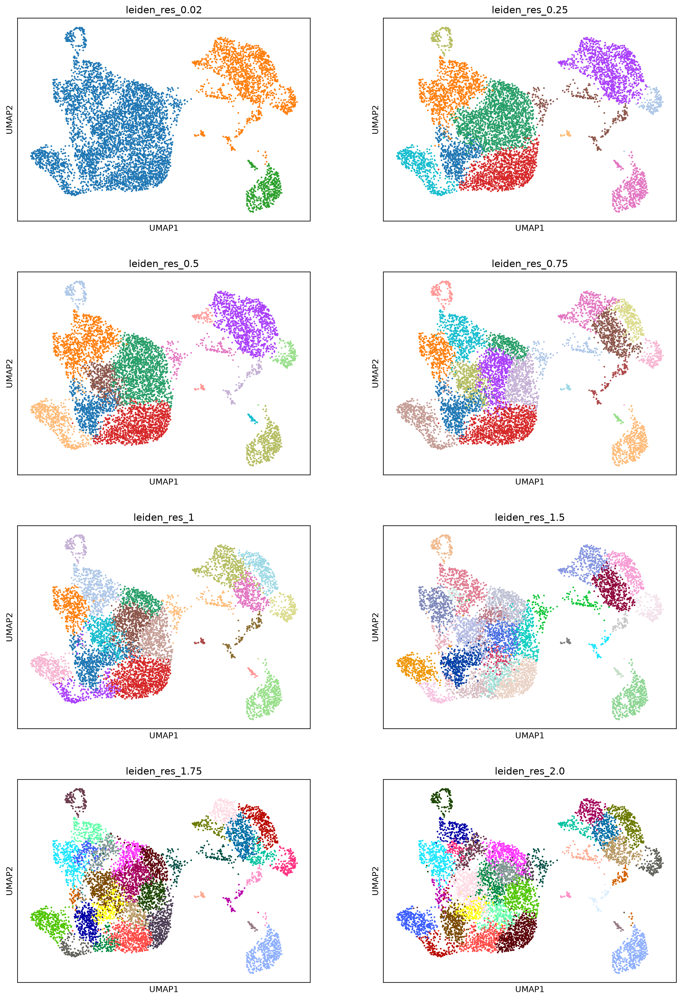

In [959]:
sc.pl.umap(
    pbmcs_qc,
    color= [f"leiden_res_{res}" for res in resoluts],
    legend_loc=None,
    ncols=2
)

Looks like maybe a resolution of 0.5 might be ideal? Maybe. This is a heavily iterative process full of trial and error. Let's stick with it for now!

## Cluster annotation

### Manual markers

The clusters above don't mean much — yet. We know the cells within these clusters are similar, but we have so far very little idea as to what they actually are. It turns out cluster annotation is a difficult problem. Most of the time, clusters are manually annotated by painstakingly looking at sets of marker genes.

Let's try the marker genes from [Single-cell Best Practices](https://www.sc-best-practices.org/cellular-structure/annotation/):

In [1018]:
# keys: cell types or populations, values: lists of marker genes
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    "ID2-hi myeloid prog": [
        "CD14",
        "ID2",
        "VCAN",
        "S100A9",
        "CLEC12A",
        "KLF4",
        "PLAUR",
    ],
    "cDC1": ["CLEC9A", "CADM1"],
    "cDC2": [
        "CST3",
        "COTL1",
        "LYZ",
        "DMXL2",
        "CLEC10A",
        "FCER1A",
    ],  # Note: DMXL2 should be negative
    "Normoblast": ["SLC4A1", "SLC25A37", "HBB", "HBA2", "HBA1", "TFRC"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    "Proerythroblast": [
        "CDK6",
        "SYNGR1",
        "HBM",
        "GYPA",
    ],  # Note HBM and GYPA are negative markers
    "NK": ["GNLY", "NKG7", "CD247", "GRIK4", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Lymph prog": [
        "VPREB1",
        "MME",
        "EBF1",
        "SSBP2",
        "BACH2",
        "CD79B",
        "IGHM",
        "PAX5",
        "PRKCE",
        "DNTT",
        "IGLL1",
    ],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    "B1 B": [
        "MS4A1",
        "SSPN",
        "ITGB1",
        "EPHA4",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "CD38",
        "XBP1",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
        "ZNF215",
    ],  # Note IGHD and IGHM are negative markers
    "Transitional B": ["MME", "CD38", "CD24", "ACSM3", "MSI2"],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    "Plasmablast": ["XBP1", "RF4", "PRDM1", "PAX5"],  # Note PAX5 is a negative marker
    "CD4+ T activated": ["CD4", "IL7R", "TRBC2", "ITGB1"],
    "CD4+ T naive": ["CD4", "IL7R", "TRBC2", "CCR7"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T activation": ["CD69", "CD38"],  # CD69 much better marker!
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
    "G/M prog": ["MPO", "BCL2", "KCNQ5", "CSF3R"],
    "HSC": ["NRIP1", "MECOM", "PROM1", "NKAIN2", "CD34"],
    "MK/E prog": [
        "ZNF385D",
        "ITGA2B",
        "RYR3",
        "PLCB1",
    ],  # Note PLCB1 is a negative marker
}

Due to QC, some of these genes may not be in our data set, let's filter them out with a helper function:

In [1019]:
def remove_missing_markers(d, adata):
    ret = {}
    for k, l in d.items():
        markers = []
        for v in l:
            if v in adata.var.index: markers.append(v)
            else: print(f"* Not found: {v:7} *")
        ret[k] = markers
    return ret

In [1020]:
marker_genes = remove_missing_markers(marker_genes, pbmcs_qc)

* Not found: HBA2    *
* Not found: HBA1    *
* Not found: HBA1    *
* Not found: HBM     *
* Not found: GYPA    *
* Not found: GRIK4   *
* Not found: RF4     *
* Not found: NKAIN2  *


Before we visualize the marker genes, let's replot the clusters:

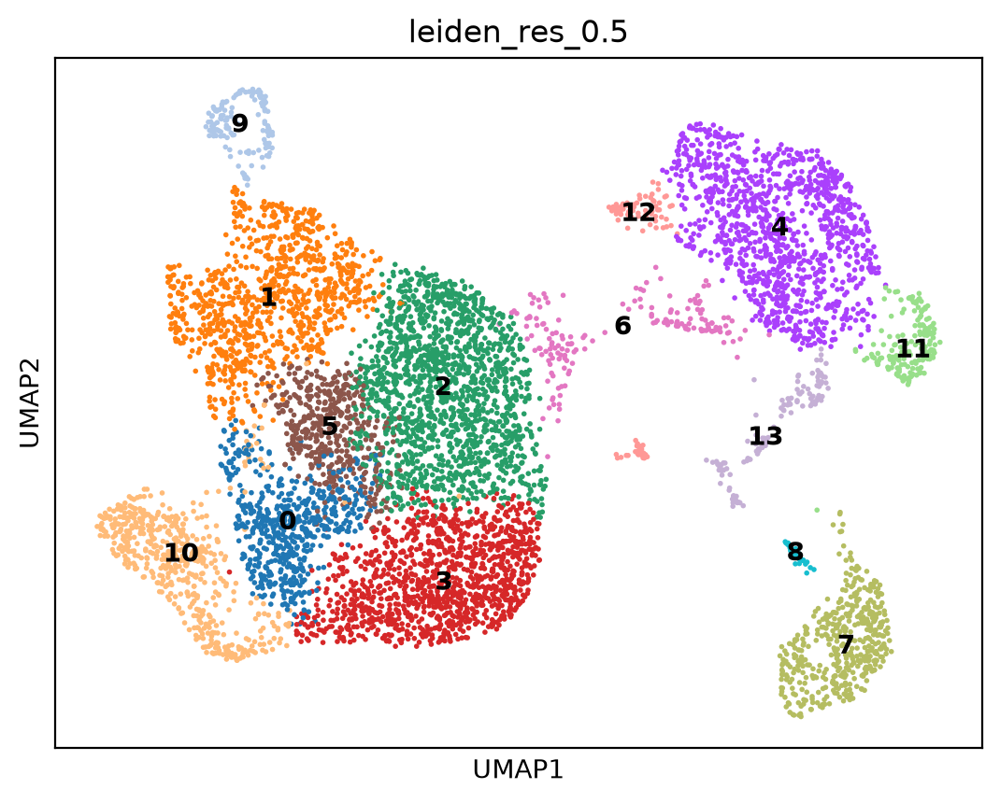

In [1021]:
sc.pl.umap(
    pbmcs_qc,
    color= "leiden_res_0.5",
    legend_loc="on data",
)

Scanpy has an incredibly helpful function to plot the expression of marker genes across clusters:

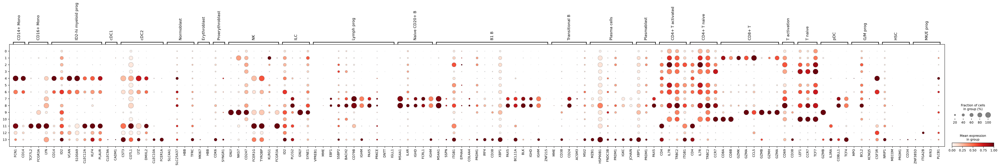

In [1022]:
sc.pl.dotplot(pbmcs_qc, marker_genes, groupby="leiden_res_0.5", standard_scale="var")

In [1031]:
overlap = sc.tl.marker_gene_overlap(pbmcs_qc, marker_genes, method='overlap_coef')
overlap

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
CD14+ Mono,0.000000,0.000000,0.000000,0.00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
CD16+ Mono,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.333333,0.333333,0.333333,0.000000,1.000000,0.000000,0.333333
ID2-hi myeloid prog,0.000000,0.000000,0.000000,0.00,0.714286,0.000000,0.857143,0.000000,0.000000,0.000000,0.000000,0.142857,0.714286,0.000000
cDC1,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
cDC2,0.000000,0.000000,0.000000,0.00,0.500000,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.333333,0.333333,0.333333
Normoblast,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Erythroblast,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Proerythroblast,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
NK,0.000000,0.285714,0.000000,0.00,0.285714,0.000000,0.285714,0.000000,0.000000,0.857143,0.000000,0.428571,0.000000,0.142857
ILC,0.000000,0.250000,0.000000,0.00,0.000000,0.000000,0.250000,0.250000,0.250000,0.500000,0.000000,0.000000,0.250000,0.000000


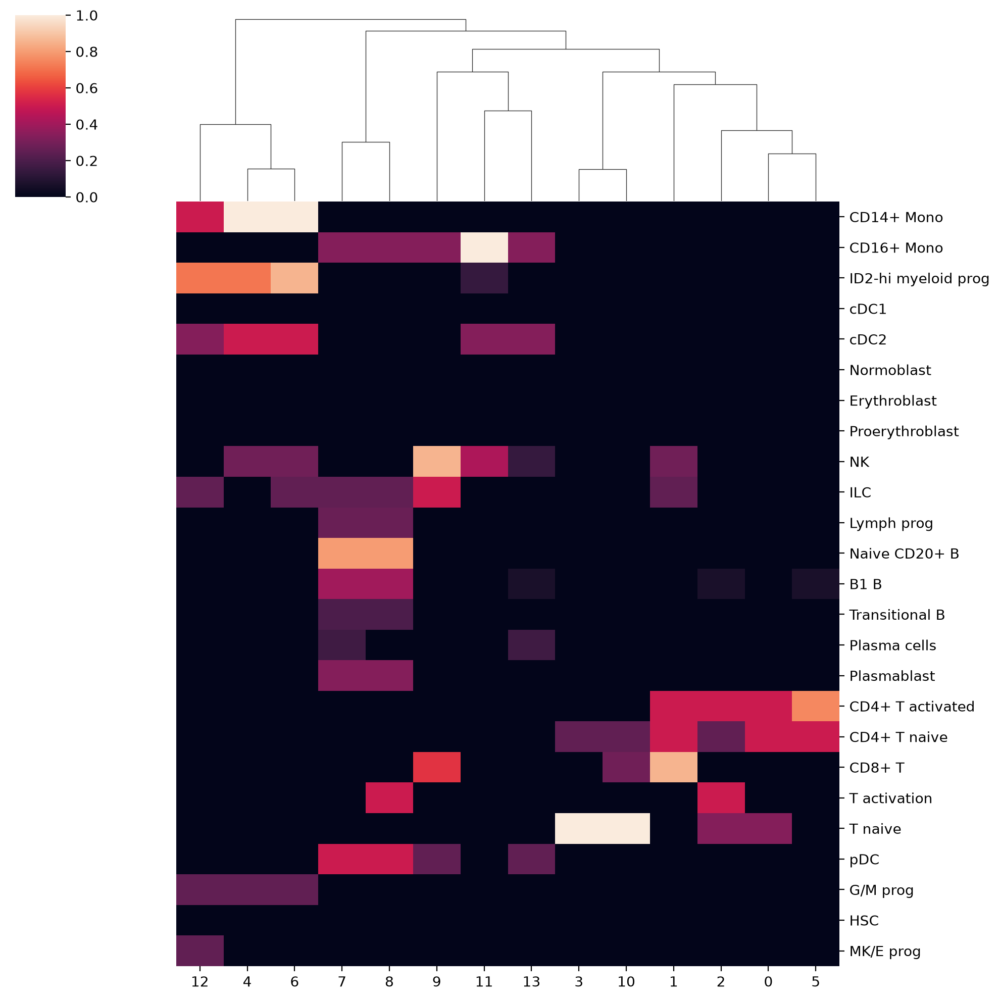

In [1034]:
sns.clustermap(overlap, col_cluster=True, row_cluster=False)

### Differentially expressed genes as markers

Another reasonable way to annotate clusters is to look at the genes that are differentially expressed in each cluster (relative to all other cells).

In [1001]:
sc.tl.rank_genes_groups(
    pbmcs_qc, 
    groupby = "leiden_res_0.5", 
    method = "wilcoxon",
    layer = 'log1p_cpm'
)

Let's visualize it:

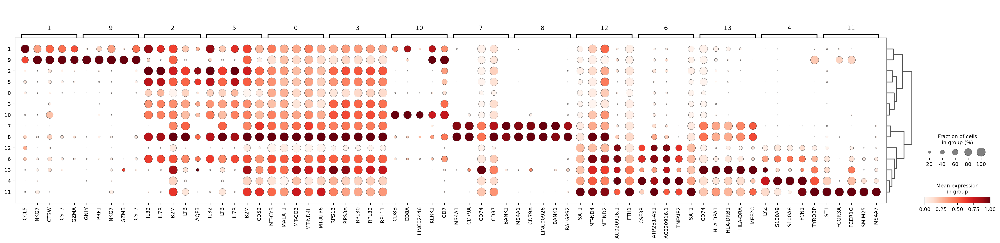

In [1023]:
sc.pl.rank_genes_groups_dotplot(
    pbmcs_qc, 
    groupby="leiden_res_0.5", 
    standard_scale="var", 
    n_genes=5
)

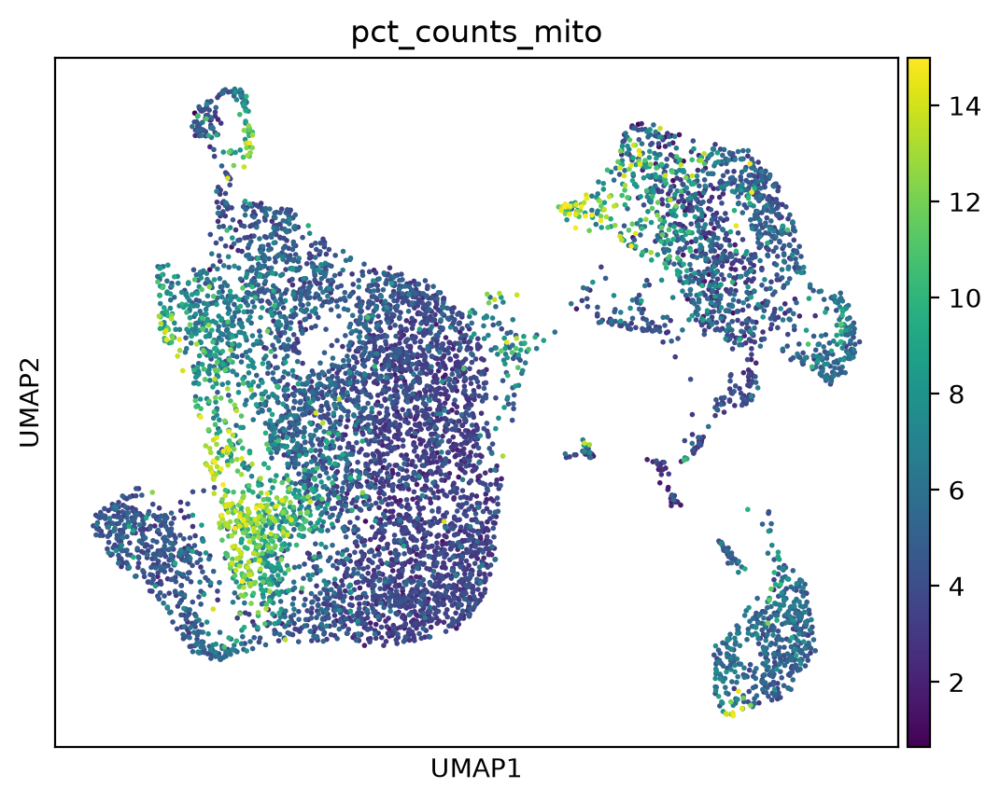

In [1005]:
sc.pl.umap(
    pbmcs_qc,
    color= "pct_counts_mito",
    legend_loc="on data",
)

## Epilogue

There is so much more that can be done with this data! Will add more about that later.